# GM12878 Analysis

1. GM12878 NIPBL ChIP-seq boxplot of jet regions provided by MIA-Jet results (top called, bottom called, top 100, bottom 100, random, randomx100)
2. GM12878 early repli-seq signal boxplot of jet regions provided by MIA-Jet results (top called, bottom called, top 100, bottom 100, random, randomx100)
3. GM12878 late repli-seq signal boxplot of jet regions provided by MIA-Jet results (top called, bottom called, top 100, bottom 100, random, randomx100)
4. GM12878 TAD insulation score boxplot of jet regions provided by MIA-Jet results (top called, bottom called, top 100, bottom 100, random, randomx100)
4. GM12878 compartment score boxplot of jet regions provided by MIA-Jet results (top called, bottom called, top 100, bottom 100, random, randomx100)

At the heart of it, we are comparing GM12878 technology i.e. in-situ, intact, RAD21 ChIA-PET, RNAPII ChIA-PET, RNAPII ChIA-DROP

In [1]:
import sys
sys.path.append('..')
from utils.plotting import plot_hic, plot_n_hic, genomic_labels, format_ticks

from func_analysis import *
from func_plotting import *
from func_iou import *
from func_pileup import *

import os
import itertools
import pybedtools
from matplotlib_venn import venn2
from collections import defaultdict
from pyBedGraph import BedGraph
import subprocess
import yaml
from scipy import stats

import bioframe as bf

from io import StringIO

In [2]:
cf = """
samples:

  GM12878_insitu-hic_4DNFI1UEG1HD_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_insitu-hic_4DNFI1UEG1HD.hic"
    genome: "hg38"
    norm: "VC_SQRT"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_insitu-hic_4DNFI1UEG1HD.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    extra_args:
    - "--diagnostic_plots"

  GM12878_microc_Wu-2025_GSE225201_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_microc_Wu-2025_GSE225201_hg38.hic"
    genome: "hg38"
    norm: "KR"
    res: "25000"
    exp: "hic"
    # mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_microc_Wu-2025_GSE225201_hg38.ice.mcool" # Not downloaded but possible
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"

  GM12878_intacthic_ENCFF318GOM_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_intacthic_ENCFF318GOM.hic"
    genome: "hg38"
    norm: "VC_SQRT"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_intacthic_ENCFF785BPC.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"

  GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38.hic"
    genome: "hg38"
    norm: "NONE"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilabs/downloaded_data/GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    sum_consistency_im: "True"

  GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38.hic"
    genome: "hg38"
    norm: "NONE"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    sum_consistency_im: "True"

  GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb:
    file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38.hic"
    genome: "hg38"
    norm: "NONE"
    res: "25000"
    exp: "hic"
    mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38.ice.mcool"
    win: "6000000"
    chroms: "all"
    root_within: "6"
    q_val: "0.5"
    consistency: "0.5"
    length: "8"
    sum_consistency_im: "True"
"""


# cf = """
# samples:

#   GM12878_insitu-hic_4DNFI1UEG1HD_25kb:
#     file: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_insitu-hic_4DNFI1UEG1HD.hic"
#     genome: "hg38"
#     norm: "VC_SQRT"
#     res: "25000"
#     exp: "hic"
#     mcool: "/nfs/turbo/umms-minjilab/downloaded_data/GM12878_insitu-hic_4DNFI1UEG1HD.ice.mcool"
#     win: "6000000"
#     chroms: "all"
#     root_within: "6"
#     q_val: "0.5"
#     consistency: "0.5"
#     length: "8"
#     extra_args:
#     - "--diagnostic_plots"

# """


config = yaml.safe_load(cf)

samples = config["samples"]

In [3]:
def read_bed(bed):
    with open(bed) as f:
        first_line = f.readline().rstrip("\n")

    if first_line.startswith("#"):
        header = first_line.lstrip("#").split("\t")
        bed = pd.read_csv(bed, sep="\t", names=header, comment="#")
        bed = bed.rename({"genomic_coords" : "unique_id", "unique_id" : "unique_id_miajet"}, axis=1)
    else:
        bed = pd.read_csv(bed, sep="\t", header=None, comment="#")
        bed = bed.rename({0 : "chrom", 1 : "start", 2 : "end", 4 : "unique_id"}, axis=1)

    if len(bed.columns) <= 3:
        # Then we need to make a fake unique_id column
        bed["unique_id"] = np.arange(len(bed))

    return bed

In [4]:
# Analysis parameters
output_name = "v2.0.3"
# output_name = "v2.0.3_white2"
# output_name = "v2.0.3_gm12878"
results_dir = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/"
save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/revision2"

os.makedirs(save_path, exist_ok=True)

result_type = "q_val_0.5-0.95" # MIA-Jet

print("RUNNING RESULT_TYPE: (CHECK IF THIS IS CORRECT FOR GM12878)", result_type)

data_name = "GM12878 cell-line"
resolution = int(25e3) 

rt = result_type

plusminus = int(25e3)

# MIA-Jet results
bed_type = "midpoint" # midpoint | jet-length

names = []
bed_top_called_list = []
bed_bottom_called_list = []
bed_top_100_list = []
bed_bottom_100_list = []
bed_random_called_list = []
bed_random_calledx100_list = []

genome = "hg38"

for key, attributes in samples.items():
    print(f"Processing experiment: {key}")
    names.append(key)

    resolution = genomic_labels(int(attributes["res"]))

    hic_name = os.path.basename(attributes["file"]).split('.hic')[0]
    fs = os.path.join(results_dir, f"{hic_name}_chr_combined_{resolution}", f"{hic_name}_chr_combined_{rt}_{resolution}_summary_table.csv")

    # Get file names 
    if bed_type == "jet-length":
        replacement_str = "jet-length.bed"
    else:
        replacement_str = f"jet-mp-{plusminus}.bed"

    # The 6 miajet results that we compare
    f_bed_top_called = fs.replace("_summary_table.csv", f"_top-called_{replacement_str}")
    f_bed_bottom_called = fs.replace("_summary_table.csv", f"_bottom-called_{replacement_str}")
    f_bed_top_100 = fs.replace("_summary_table.csv", f"_top-100_{replacement_str}")
    f_bed_bottom_100 = fs.replace("_summary_table.csv", f"_bottom-100_{replacement_str}")
    f_bed_random_called = fs.replace("_summary_table.csv", f"_random-called_{replacement_str}")
    f_bed_random_calledx100 = fs.replace("_summary_table.csv", f"_random-calledx100_{replacement_str}")

    bed_top_called = read_bed(f_bed_top_called)
    bed_bottom_called = read_bed(f_bed_bottom_called)
    bed_top_100 = read_bed(f_bed_top_100)
    bed_bottom_100 = read_bed(f_bed_bottom_100)
    bed_random_called = read_bed(f_bed_random_called)
    bed_random_calledx100 = read_bed(f_bed_random_calledx100)

    bed_top_called_list.append(bed_top_called)
    bed_bottom_called_list.append(bed_bottom_called)
    bed_top_100_list.append(bed_top_100)
    bed_bottom_100_list.append(bed_bottom_100)
    bed_random_called_list.append(bed_random_called)
    bed_random_calledx100_list.append(bed_random_calledx100)

# Copy and paste the above code for NIPBL results with fixed plusminus
plusminus_nipbl = int(25e3) # Separate NIPBL range
bed_top_called_list_nipbl = []
bed_bottom_called_list_nipbl = []
bed_top_100_list_nipbl = []
bed_bottom_100_list_nipbl = []
bed_random_called_list_nipbl = []
bed_random_calledx100_list_nipbl = []

for key, attributes in samples.items():
    print(f"Processing experiment: {key}")
    # names.append(key)

    resolution = genomic_labels(int(attributes["res"]))

    hic_name = os.path.basename(attributes["file"]).split('.hic')[0]
    fs = os.path.join(results_dir, f"{hic_name}_chr_combined_{resolution}", f"{hic_name}_chr_combined_{rt}_{resolution}_summary_table.csv")

    # Get file names 
    if bed_type == "jet-length":
        replacement_str = "jet-length.bed"
    else:
        replacement_str = f"jet-mp-{plusminus_nipbl}.bed"

    # The 6 miajet results that we compare
    f_bed_top_called = fs.replace("_summary_table.csv", f"_top-called_{replacement_str}")
    f_bed_bottom_called = fs.replace("_summary_table.csv", f"_bottom-called_{replacement_str}")
    f_bed_top_100 = fs.replace("_summary_table.csv", f"_top-100_{replacement_str}")
    f_bed_bottom_100 = fs.replace("_summary_table.csv", f"_bottom-100_{replacement_str}")
    f_bed_random_called = fs.replace("_summary_table.csv", f"_random-called_{replacement_str}")
    f_bed_random_calledx100 = fs.replace("_summary_table.csv", f"_random-calledx100_{replacement_str}")

    bed_top_called = read_bed(f_bed_top_called)
    bed_bottom_called = read_bed(f_bed_bottom_called)
    bed_top_100 = read_bed(f_bed_top_100)
    bed_bottom_100 = read_bed(f_bed_bottom_100)
    bed_random_called = read_bed(f_bed_random_called)
    bed_random_calledx100 = read_bed(f_bed_random_calledx100)

    bed_top_called_list_nipbl.append(bed_top_called)
    bed_bottom_called_list_nipbl.append(bed_bottom_called)
    bed_top_100_list_nipbl.append(bed_top_100)
    bed_bottom_100_list_nipbl.append(bed_bottom_100)
    bed_random_called_list_nipbl.append(bed_random_called)
    bed_random_calledx100_list_nipbl.append(bed_random_calledx100)


RUNNING RESULT_TYPE: (CHECK IF THIS IS CORRECT FOR GM12878) q_val_0.5-0.95
Processing experiment: GM12878_insitu-hic_4DNFI1UEG1HD_25kb
Processing experiment: GM12878_microc_Wu-2025_GSE225201_hg38_25kb
Processing experiment: GM12878_intacthic_ENCFF318GOM_25kb
Processing experiment: GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
Processing experiment: GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
Processing experiment: GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb
Processing experiment: GM12878_insitu-hic_4DNFI1UEG1HD_25kb
Processing experiment: GM12878_microc_Wu-2025_GSE225201_hg38_25kb
Processing experiment: GM12878_intacthic_ENCFF318GOM_25kb
Processing experiment: GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
Processing experiment: GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
Processing experiment: GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb


In [5]:
names_abrev = [
    "Insitu Hi-C", "Micro-C", "Intact Hi-C", "RAD21 ChIA-PET", "RNAPII ChIA-PET", "RNAPII ChIA-Drop"
]

# names_abrev =  ["Insitu Hi-C"]


In [6]:
chromsizes = bf.fetch_chromsizes(genome, as_bed=True)
common_chroms = list(chromsizes["chrom"].values)
# New
common_chroms.remove('chrY')
common_chroms.remove('chrM')

In [7]:
common_chroms

['chr1',
 'chr2',
 'chr3',
 'chr4',
 'chr5',
 'chr6',
 'chr7',
 'chr8',
 'chr9',
 'chr10',
 'chr11',
 'chr12',
 'chr13',
 'chr14',
 'chr15',
 'chr16',
 'chr17',
 'chr18',
 'chr19',
 'chr20',
 'chr21',
 'chr22',
 'chrX']

In [8]:
miajet_result_types = [
    "Top called",
    # "Bottom called",
    "Top 100",
    # "Bottom 100",
    "Random called",
    "Random called x100",
]

miajet_result_tables = [
    bed_top_called_list,
    # bed_bottom_called_list,
    bed_top_100_list,
    # bed_bottom_100_list,
    bed_random_called_list,
    bed_random_calledx100_list,
]


## ECDF to closest IZ zone

In [9]:
f_repliseq_iz_zone = "/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/GSM923451_hg19_wgEncodeUwRepliSeqGm12878PkRep1.bed.gz"
# f_repliseq_iz_zone = "/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/GSM923451_hg19_wgEncodeUwRepliSeqGm12878ValleysRep1.bed.gz"
# f_repliseq_iz_zone = "/nfs/turbo/umms-minjilab/downloaded_data/miajet_data_temp/13059_2021_2390_MOESM2_ESM.xlsx" # GM12878 IZs

df_iz = pd.read_csv(f_repliseq_iz_zone, sep='\t', header=None, names=["chrom", "start", "end", "name", "strand", "6", "7", "8", "9"]) # for the bed.gz
# df_iz = pd.read_excel(f_repliseq_iz_zone, header=1) # for the excel

name = os.path.basename(f_repliseq_iz_zone).split('.')[0]
name

'GSM923451_hg19_wgEncodeUwRepliSeqGm12878PkRep1'

In [10]:
df_iz

,chrom,start,end,name,strand,6,7,8,9
0,chr1,227500,228500,.,600,+,.,.,"179,45,0"
1,chr1,620500,621500,.,700,+,.,.,"179,45,0"
2,chr1,986500,987500,.,1000,+,.,.,"179,45,0"
3,chr1,1745500,1746500,.,900,+,.,.,"179,45,0"
4,chr1,1912500,1913500,.,900,+,.,.,"179,45,0"
...,...,...,...,...,...,...,...,...,...
4536,chrX,152265500,152266500,.,400,+,.,.,"179,45,0"
4537,chrX,153205500,153206500,.,500,+,.,.,"179,45,0"
4538,chrX,153646500,153647500,.,500,+,.,.,"179,45,0"
4539,chrX,154310500,154311500,.,400,+,.,.,"179,45,0"


In [11]:
# Need to remap hg19 to hg38 for ALL the IZ files above (they are all hg19)
f_liftover = "/nfs/turbo/umms-minjilab/packages/linux.x86_64/liftOver"
f_chain = "/nfs/turbo/umms-minjilab/processing/genomes/hg19ToHg38.over.chain"

def liftover(df, chrom_col, start_col, end_col, liftover_path, chain_path, work_dir="../temp"):
    """
    Perform UCSC liftOver using fixed filenames in work_dir:
      - writes work_dir/in.bed
      - produces work_dir/out.bed and work_dir/unmapped.bed
    Returns df with chrom_new, start_new, end_new appended
    """
    os.makedirs(work_dir, exist_ok=True)

    bed_path = f"{work_dir}/in.bed"
    out_path = f"{work_dir}/out.bed"
    unmapped_path = f"{work_dir}/unmapped.bed"

    # make bed dataframe for export
    bed_df = pd.DataFrame({
        'chrom': df[chrom_col].astype(str),
        'start': np.round(df[start_col]).astype(int),
        'end':   np.round(df[end_col]).astype(int),
        "index": np.arange(len(df)),
    })
    bed_df.to_csv(bed_path, sep='\t', header=False, index=False)

    # run liftover
    subprocess.run(
        [liftover_path, bed_path, chain_path, out_path, unmapped_path],
        check=True
    )

    # read results
    df_out = pd.read_csv(out_path, sep='\t', header=None,
                         names=[f'{chrom_col} remapped', f'{start_col} remapped', f'{end_col} remapped', "index"])

    shell = pd.DataFrame(index=df.index, columns=[f'{chrom_col} remapped', f'{start_col} remapped', f'{end_col} remapped'])

    shell.loc[df_out["index"].values] = df_out.iloc[:, :3].values

    return pd.concat([df, shell], axis=1)



def remap_bed_df(bed, work_suffix):
    bed = liftover(
        bed,
        chrom_col="chrom",
        start_col="start",
        end_col="end",
        liftover_path=f_liftover,
        chain_path=f_chain,
        work_dir=os.path.join(save_path, f"liftover_{key}_{work_suffix}")
    )

    # keep only successfully mapped rows
    bed = bed.dropna(subset=["chrom remapped", "start remapped", "end remapped"]).copy()

    # replace original coordinates with remapped ones
    bed["chrom"] = bed["chrom remapped"]
    bed["start"] = bed["start remapped"].astype(int)
    bed["end"] = bed["end remapped"].astype(int)

    # refresh coordinate-based ID
    if "unique_id" in bed.columns:
        bed["unique_id"] = (
            bed["chrom"].astype(str) + ":" +
            bed["start"].astype(str) + "-" +
            bed["end"].astype(str)
        )

    # optional cleanup
    bed = bed.drop(columns=["chrom remapped", "start remapped", "end remapped"])

    return bed

In [12]:
df_iz_remapped = remap_bed_df(df_iz, name)

Reading liftover chains
Mapping coordinates


In [13]:
# Save intermediary file (lifted over)
df_iz_remapped.to_csv(os.path.join(save_path, f_repliseq_iz_zone.replace('hg19', 'hg38').replace('.bed.gz', '.bed')), sep='\t', index=False)

In [14]:
import pybedtools
from pybedtools import BedTool
from statsmodels.distributions.empirical_distribution import ECDF
from scipy.stats import ks_2samp


def df_to_bedtool(df, cols=("chrom", "start", "end")):
    """
    Convert a dataframe with chrom/start/end columns into a sorted BED3 BedTool.
    Keeps only BED3 columns so the closest distance is always the last field.
    """
    bed_df = df.loc[:, list(cols)].copy()
    bed_df["start"] = bed_df["start"].astype(int)
    bed_df["end"] = bed_df["end"].astype(int)

    bed_df = bed_df.dropna()
    bed_df = bed_df.loc[bed_df["end"] > bed_df["start"]]

    bed_df = bed_df.sort_values(["chrom", "start", "end"], kind="mergesort")
    return BedTool.from_dataframe(bed_df).sort()


def make_iz_bedtool(df_iz_subset):
    """
    Build a merged IZ BedTool using bedtools merge instead of custom merge_intervals().
    """
    if df_iz_subset.empty:
        return None

    iz_bt = df_to_bedtool(df_iz_subset, cols=("chrom", "start", "end"))
    return iz_bt.merge()


def distances_to_iz_closest(df, iz_bt):
    """
    Distance from each interval in df to the closest merged IZ interval.

    Equivalent behavior to your manual search:
      - overlapping IZ => distance 0
      - otherwise nearest genomic gap
      - intervals on chromosomes with no IZ are ignored
    """
    if df.empty or iz_bt is None:
        return np.array([], dtype=float)

    a_bt = df_to_bedtool(df, cols=("chrom", "start", "end"))

    closest_bt = a_bt.closest(
        iz_bt,
        d=True,       # append distance as last column
        t="first",    # avoid duplicate rows for ties
    )

    dists = []
    for rec in closest_bt:
        # With BED3 A and BED3 B, distance is the final field.
        # If no B feature exists on the same chromosome, bedtools reports -1 fields.
        try:
            dist = int(rec.fields[-1])
        except ValueError:
            continue

        if dist >= 0:
            dists.append(dist)

    return np.asarray(dists, dtype=float)


def ecdf_xy(values):
    """
    ECDF using statsmodels instead of a custom ECDF implementation.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.array([]), np.array([])

    f = ECDF(values)
    finite = np.isfinite(f.x)

    return f.x[finite], f.y[finite]

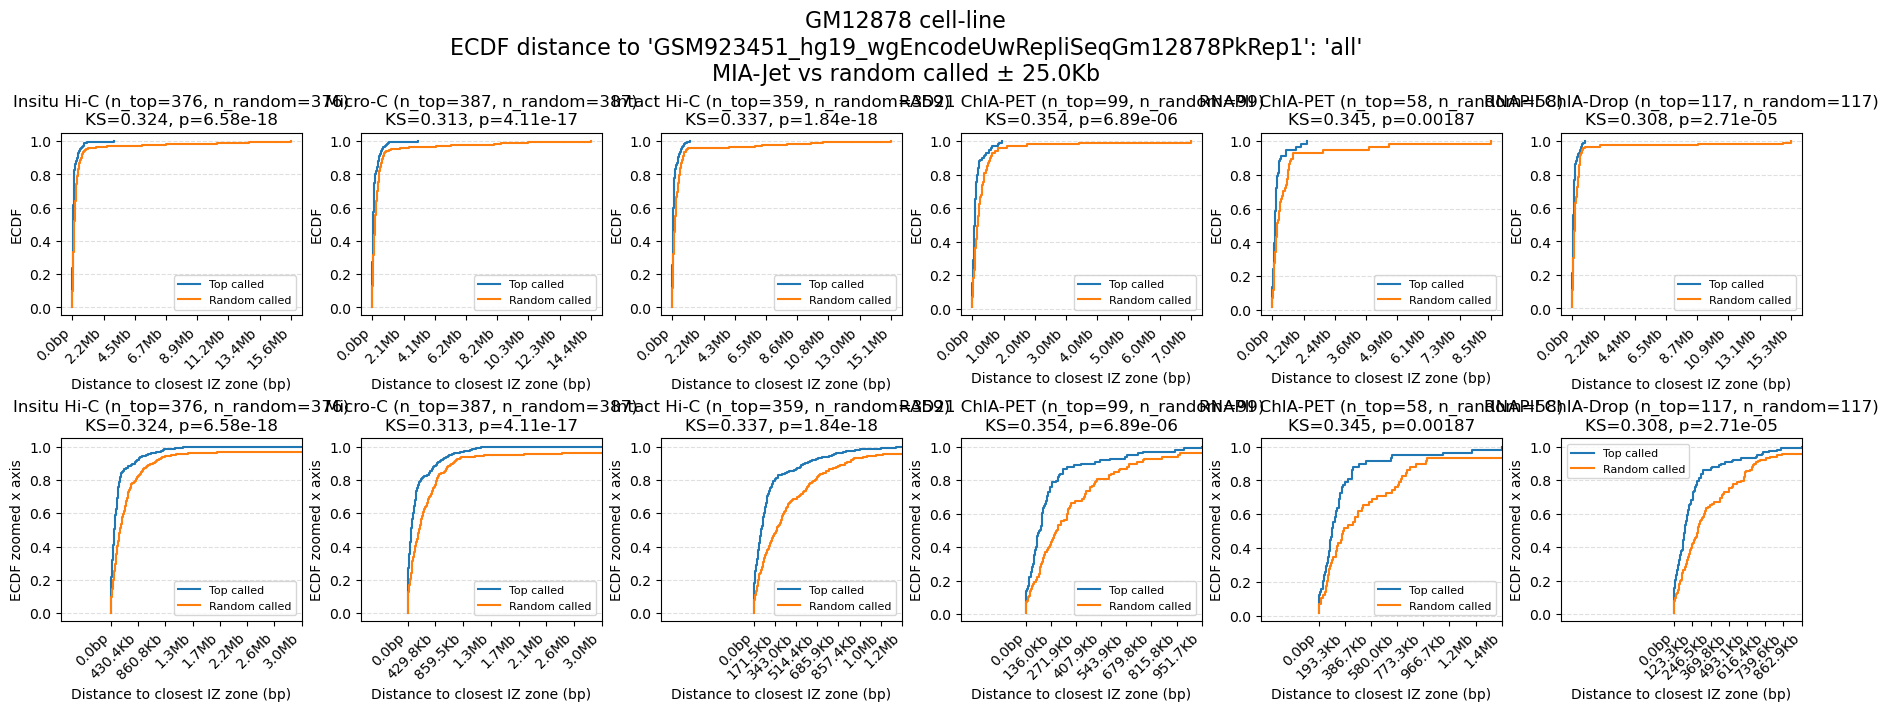

In [15]:
iz_subset = "all"

if iz_subset != "all":
    df_iz_subset = (
        df_iz_remapped
        .loc[df_iz_remapped["name"] == iz_subset]
        .reset_index(drop=True)
    )
else:
    df_iz_subset = df_iz_remapped.copy()

# Replaces iz_by_chrom + merge_intervals()
iz_bt = make_iz_bedtool(df_iz_subset)

n_plots = len(bed_top_called_list)
fig, axes = plt.subplots(
    2,
    n_plots,
    figsize=(3 * n_plots, 7),
    layout="constrained",
)

axes = np.array(axes).reshape(2, n_plots)

num_ticks = 8

for i in range(n_plots):
    ax = axes[0, i]
    ax_zoom = axes[1, i]

    top_dist = distances_to_iz_closest(bed_top_called_list[i], iz_bt)
    rnd_dist = distances_to_iz_closest(bed_random_called_list[i], iz_bt)

    if len(top_dist) == 0 or len(rnd_dist) == 0:
        for a in [ax, ax_zoom]:
            a.set_title(f"{names_abrev[i]}\nNo valid distances")
            a.set_xlabel("Distance to closest IZ zone (bp)")
            a.set_ylabel("ECDF")
            a.grid(axis="y", linestyle="--", alpha=0.4)
        continue

    x_top, y_top = ecdf_xy(top_dist)
    x_rnd, y_rnd = ecdf_xy(rnd_dist)

    ks_stat, ks_pval = ks_2samp(top_dist, rnd_dist)

    for j, a in enumerate([ax, ax_zoom]):
        a.step(x_top, y_top, where="post", label="Top called")
        a.step(x_rnd, y_rnd, where="post", label="Random called")

        title = (
            f"{names_abrev[i]} "
            f"(n_top={len(top_dist)}, n_random={len(rnd_dist)})\n"
            f"KS={ks_stat:.3f}, p={ks_pval:.3g}"
        )
        a.set_title(title)
        a.set_xlabel("Distance to closest IZ zone (bp)")

        if j == 1:
            a.set_ylabel("ECDF zoomed x axis")
        else:
            a.set_ylabel("ECDF")

        a.grid(axis="y", linestyle="--", alpha=0.4)
        a.legend(fontsize=8)

    # Same zooming behavior as your original code:
    # zoom to the max distance observed in top_dist.
    ax_zoom.set_xlim(None, x_top[-1])

    xticks = np.linspace(
        min(x_top[0], x_rnd[0]),
        max(x_top[-1], x_rnd[-1]),
        num_ticks,
    )
    ax.set_xticks(xticks)
    ax.set_xticklabels(
        [genomic_labels(x, N=1) for x in xticks],
        fontsize=10,
        rotation=45,
        ha="right",
    )

    xticks = np.linspace(
        min(x_top[0], x_rnd[0]),
        x_top[-1],
        num_ticks,
    )
    ax_zoom.set_xticks(xticks)
    ax_zoom.set_xticklabels(
        [genomic_labels(x, N=1) for x in xticks],
        fontsize=10,
        rotation=45,
        ha="right",
    )


fig.suptitle(
    f"{data_name}\n"
    f"ECDF distance to '{name}': '{iz_subset}'\n"
    f"MIA-Jet vs random called ± {genomic_labels(plusminus, N=1)}",
    fontsize=16,
)

save_fname = (
    f"{save_path}/{data_name}_{name}_{rt}_"
    f"Top-called_vs_Random-called_"
    f"ECDF_{plusminus}.png"
)

plt.savefig(save_fname, dpi=500)

plt.show()

## NIPBL ChIP-seq

In [16]:
# READ IN CHIP-SEQ
f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"

chip_files = [
    '/nfs/turbo/umms-minjilab/processing/results/CHG0030/CHG0030.q30.nr.sorted.bedgraph',
]

chip_names = [
    "NIPBL ChIP-seq CHG0030",
]

chip_names_abrev = ["NIPBL"]

In [17]:
observed_type = "Top called" # "Top called" | "Top 100"
background_type = "Random called" # "Random called" | "Random called x100"

miajet_mapping = {
    "Top called": bed_top_called_list,
    "Top 100": bed_top_100_list,
    "Random called": bed_random_called_list,
    "Random called x100": bed_random_calledx100_list,
}

observed_table = miajet_mapping[observed_type]
background_table = miajet_mapping[background_type]

stat = "max"
chipseq_idx = 0
chipseq_resolution = 10000  # 10 kb

obs_intervals = [df.reset_index(drop=True) for df in observed_table]
bg_intervals = [df.reset_index(drop=True) for df in background_table]

# One file read for all observed intervals
chipseq_obs_dicts = extract_chipseq_values(
    [chip_files[chipseq_idx]],
    obs_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat
)[0]  # list of dicts, len is len(names)

# One file read for all background intervals
chipseq_bg_dicts = extract_chipseq_values(
    [chip_files[chipseq_idx]],
    bg_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat
)[0]

# Convert dicts to arrays (one array per experiment)
chipseq_obs = [np.asarray(list(d.values())) for d in chipseq_obs_dicts]
chipseq_bg  = [np.asarray(list(d.values())) for d in chipseq_bg_dicts]

# Pack for plotting cell
collected_chipseq = {
    "observed_type": observed_type,
    "background_type": background_type,
    "stat": stat,
    "chipseq_idx": chipseq_idx,
    "chipseq_resolution": chipseq_resolution,
    "obs_values": chipseq_obs,
    "bg_values": chipseq_bg,
}

chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is already loaded
chr21 is already loaded
chr22 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is al

No jets called for chromosome chr13 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr19 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr18 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr21 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr6 by GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is already loaded
chr21 is already loaded
chr22 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is al

No jets called for chromosome chr13 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr19 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr18 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr21 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr6 by GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb


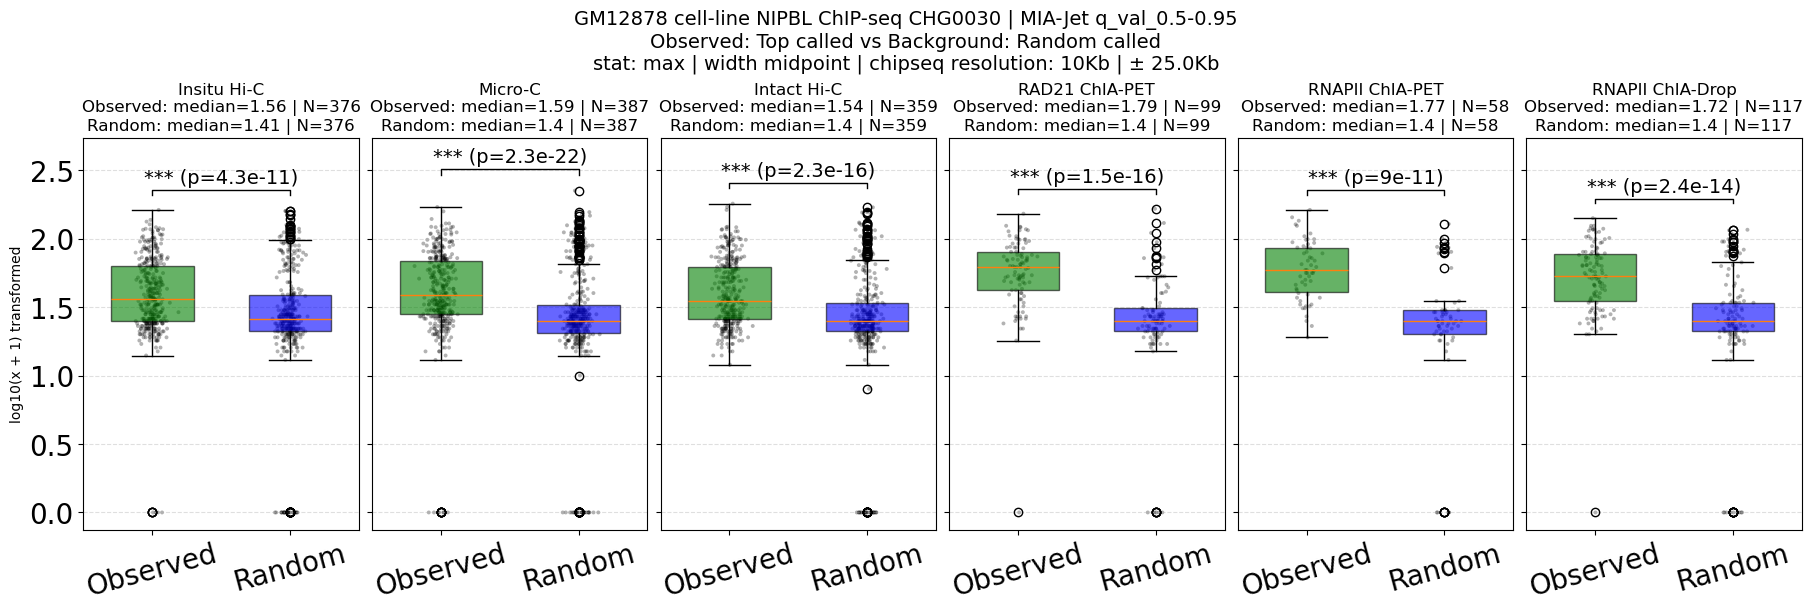

In [18]:
# PLOTTING
obs_type = collected_chipseq["observed_type"]
bg_type = collected_chipseq["background_type"]
stat = collected_chipseq["stat"]
chipseq_idx = collected_chipseq["chipseq_idx"]
chipseq_resolution = collected_chipseq["chipseq_resolution"]

obs_values = collected_chipseq["obs_values"]
bg_values = collected_chipseq["bg_values"]

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
obs_col, bg_col = "green", "blue"

num_exp = len(names)
fig, axes = plt.subplots(1, num_exp, figsize=(4 * num_exp * 0.75, 6),
                         sharey=True, layout="constrained")

axes = np.atleast_1d(axes)

for i, ax in enumerate(np.ravel(axes)):
    data_pair = []
    for raw_vals in (obs_values[i], bg_values[i]):
        vals = raw_vals[~np.isnan(raw_vals)]
        vals = np.clip(vals, 0, None)
        vals = np.log10(vals + 1)
        data_pair.append(vals)

    positions = [1, 2]
    add_pairwise_sig(ax, positions, data_pair, fontsize=14)

    bp = ax.boxplot(data_pair, patch_artist=True,
                    positions=positions, widths=0.6)
    bp['boxes'][0].set_facecolor(obs_col); bp['boxes'][0].set_alpha(0.6)
    bp['boxes'][1].set_facecolor(bg_col);  bp['boxes'][1].set_alpha(0.6)

    for pos, vals in zip(positions, data_pair):
        x = np.full_like(vals, pos, dtype=float) + np.random.normal(0, 0.05, len(vals))
        ax.scatter(x, vals, s=8, alpha=0.3, color='k', edgecolor='none')

    ax.set_xticks(positions)
    ax.set_xticklabels(["Observed", "Random"], rotation=15, ha="center", fontsize=20)

    title_boxstat = title_boxplot(names_abrev[i], ["Observed", "Random"], data_pair)
    ax.set_title(title_boxstat)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("log10(x + 1) transformed")

# after the plotting loop, before savefig/show
pad = 0.1  # fixed amount in data units
ymin, ymax = axes[0].get_ylim()
axes[0].set_ylim(ymin, ymax + pad)
y_tick_size = 20
for ax in np.ravel(axes):
    ax.tick_params(axis="y", labelsize=y_tick_size)

fig.suptitle(
    f"{data_name} {chip_names[chipseq_idx]} | MIA-Jet {rt}\n"
    f"Observed: {obs_type} vs Background: {bg_type}\n"
    f"stat: {stat} | width {bed_type} | chipseq resolution: {genomic_labels(chipseq_resolution)} | ± {genomic_labels(plusminus, N=1)}",
    fontsize=14
)

save_fname = (
    f"{save_path}/{data_name}_{bed_type}_{rt}_"
    f"{obs_type.replace(' ', '-')}_vs_{bg_type.replace(' ', '-')}_"
    f"{chip_names_abrev[chipseq_idx]}_chipseq_comparison_{plusminus}.png"
)

plt.savefig(save_fname, dpi=300)

plt.show()

## TAD Insulation Score

In [19]:
# READ IN CHIP-SEQ
f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"

chip_files = [
    '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_hic_insulation_score_Rao-2014_4DNFIBMOGOZC_hg38.bigWig'
]

chip_names = [
    "GM12878_hic_insulation_score_Rao-2014_4DNFIBMOGOZC_hg38",
]

chip_names_abrev = ["Insulation Score"]

In [20]:
observed_type = "Top called" # "Top called" | "Top 100"
background_type = "Random called" # "Random called" | "Random called x100"

miajet_mapping = {
    "Top called": bed_top_called_list,
    "Top 100": bed_top_100_list,
    "Random called": bed_random_called_list,
    "Random called x100": bed_random_calledx100_list,
}

observed_table = miajet_mapping[observed_type]
background_table = miajet_mapping[background_type]

if bed_type == "midpoint":
    stat = "max"
else:
    stat = "mean"
    
chipseq_idx = 0
chipseq_resolution = 10000  # 10 kb

obs_intervals = [df.reset_index(drop=True) for df in observed_table]
bg_intervals = [df.reset_index(drop=True) for df in background_table]

# One file read for all observed intervals
chipseq_obs_dicts = extract_chipseq_values(
    [chip_files[chipseq_idx]],
    obs_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat
)[0]  # list of dicts, len is len(names)

# One file read for all background intervals
chipseq_bg_dicts = extract_chipseq_values(
    [chip_files[chipseq_idx]],
    bg_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat
)[0]

# Convert dicts to arrays (one array per experiment)
chipseq_obs = [np.asarray(list(d.values())) for d in chipseq_obs_dicts]
chipseq_bg  = [np.asarray(list(d.values())) for d in chipseq_bg_dicts]

# Pack for plotting cell
collected_chipseq = {
    "observed_type": observed_type,
    "background_type": background_type,
    "stat": stat,
    "chipseq_idx": chipseq_idx,
    "chipseq_resolution": chipseq_resolution,
    "obs_values": chipseq_obs,
    "bg_values": chipseq_bg,
}

chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is already loaded
chr21 is already loaded
chr22 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is al

No jets called for chromosome chr13 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr19 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr18 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr21 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr6 by GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is already loaded
chr21 is already loaded
chr22 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is al

No jets called for chromosome chr13 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr19 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr18 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr21 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr6 by GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb


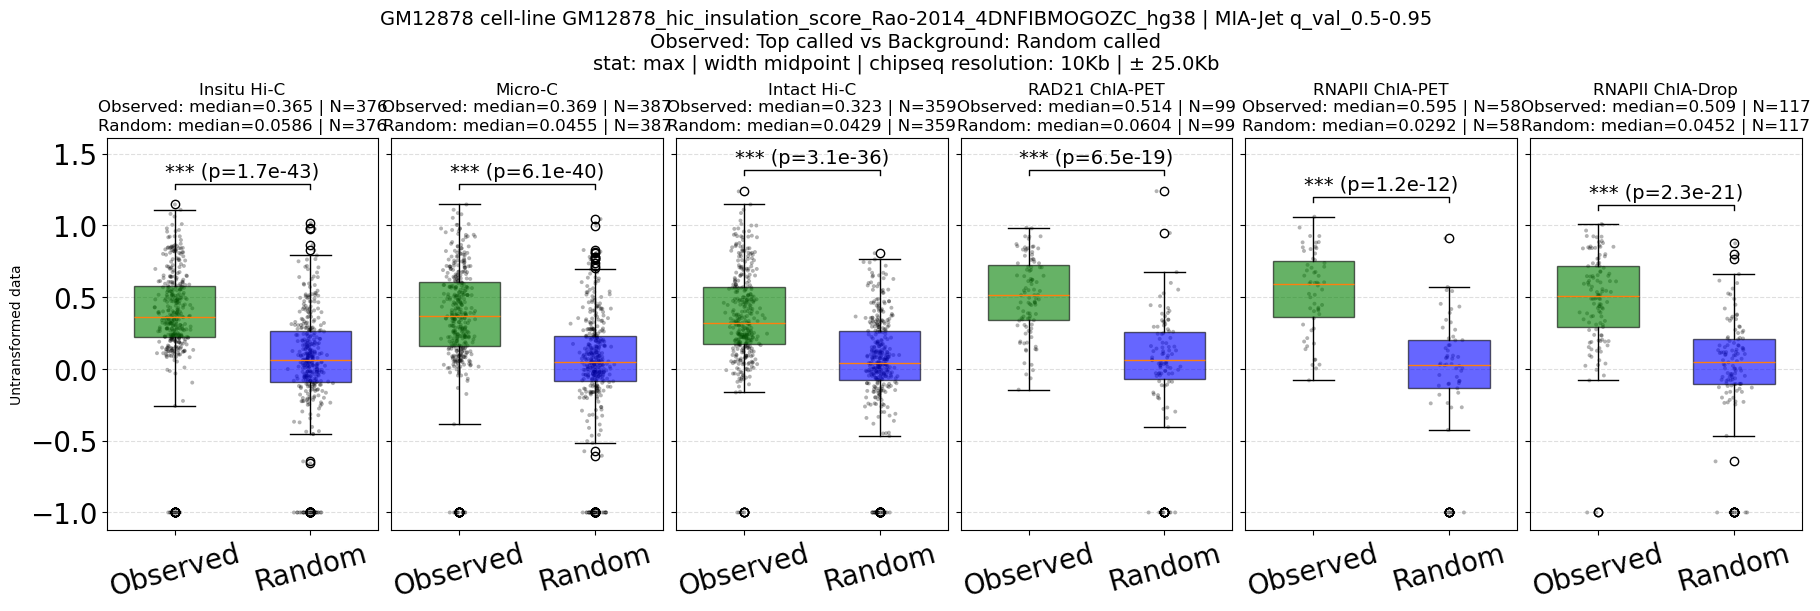

In [21]:
# PLOTTING
obs_type = collected_chipseq["observed_type"]
bg_type = collected_chipseq["background_type"]
stat = collected_chipseq["stat"]
chipseq_idx = collected_chipseq["chipseq_idx"]
chipseq_resolution = collected_chipseq["chipseq_resolution"]

obs_values = collected_chipseq["obs_values"]
bg_values = collected_chipseq["bg_values"]

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
obs_col, bg_col = "green", "blue"

num_exp = len(names)
fig, axes = plt.subplots(1, num_exp, figsize=(4 * num_exp * 0.75, 6),
                         sharey=True, layout="constrained")

axes = np.atleast_1d(axes)

for i, ax in enumerate(np.ravel(axes)):
    data_pair = []
    for raw_vals in (obs_values[i], bg_values[i]):
        vals = raw_vals[~np.isnan(raw_vals)]
        # vals = np.clip(vals, 0, None)
        # vals = np.log10(vals + 1)
        data_pair.append(vals)

    positions = [1, 2]
    add_pairwise_sig(ax, positions, data_pair, fontsize=14)

    bp = ax.boxplot(data_pair, patch_artist=True,
                    positions=positions, widths=0.6)
    bp['boxes'][0].set_facecolor(obs_col); bp['boxes'][0].set_alpha(0.6)
    bp['boxes'][1].set_facecolor(bg_col);  bp['boxes'][1].set_alpha(0.6)

    for pos, vals in zip(positions, data_pair):
        x = np.full_like(vals, pos, dtype=float) + np.random.normal(0, 0.05, len(vals))
        ax.scatter(x, vals, s=8, alpha=0.3, color='k', edgecolor='none')

    ax.set_xticks(positions)
    ax.set_xticklabels(["Observed", "Random"], rotation=15, ha="center", fontsize=20)

    title_boxstat = title_boxplot(names_abrev[i], ["Observed", "Random"], data_pair)
    ax.set_title(title_boxstat)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("Untransformed data")

# after the plotting loop, before savefig/show
pad = 0.1  # fixed amount in data units
ymin, ymax = axes[0].get_ylim()
axes[0].set_ylim(ymin, ymax + pad)
y_tick_size = 20
for ax in np.ravel(axes):
    ax.tick_params(axis="y", labelsize=y_tick_size)

fig.suptitle(
    f"{data_name} {chip_names[chipseq_idx]} | MIA-Jet {rt}\n"
    f"Observed: {obs_type} vs Background: {bg_type}\n"
    f"stat: {stat} | width {bed_type} | chipseq resolution: {genomic_labels(chipseq_resolution)} | ± {genomic_labels(plusminus, N=1)}",
    fontsize=14
)

save_fname = (
    f"{save_path}/{data_name}_{bed_type}_{rt}_"
    f"{obs_type.replace(' ', '-')}_vs_{bg_type.replace(' ', '-')}_"
    f"{chip_names_abrev[chipseq_idx]}_chipseq_comparison_{plusminus}.png"
)
plt.savefig(save_fname, dpi=300)

plt.show()

## A/B Compartment Score

In [22]:
# READ IN CHIP-SEQ
f_chrom_sizes = "/nfs/turbo/umms-minjilab/processing/genomes/hg38/hg38.chrom.sizes"

chip_files = [
    '/nfs/turbo/umms-minjilab/downloaded_data/GM12878_hic_compartment_score_Rao-2014_4DNFILYQ1PAY_hg38.bigWig'
]

chip_names = [
    "GM12878_hic_compartment_score_Rao-2014_4DNFILYQ1PAY_hg38",
]

chip_names_abrev = ["Compartment Score"]

In [23]:
observed_type = "Top called" # "Top called" | "Top 100"
background_type = "Random called" # "Random called" | "Random called x100"

miajet_mapping = {
    "Top called": bed_top_called_list,
    "Top 100": bed_top_100_list,
    "Random called": bed_random_called_list,
    "Random called x100": bed_random_calledx100_list,
}

observed_table = miajet_mapping[observed_type]
background_table = miajet_mapping[background_type]

if bed_type == "midpoint":
    stat = "max"
else:
    stat = "mean"
    
chipseq_idx = 0
chipseq_resolution = 10000  # 10 kb

obs_intervals = [df.reset_index(drop=True) for df in observed_table]
bg_intervals = [df.reset_index(drop=True) for df in background_table]

# One file read for all observed intervals
chipseq_obs_dicts = extract_chipseq_values(
    [chip_files[chipseq_idx]],
    obs_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat
)[0]  # list of dicts, len is len(names)

# One file read for all background intervals
chipseq_bg_dicts = extract_chipseq_values(
    [chip_files[chipseq_idx]],
    bg_intervals,
    f_chrom_sizes,
    common_chroms,
    names,
    stat=stat
)[0]

# Convert dicts to arrays (one array per experiment)
chipseq_obs = [np.asarray(list(d.values())) for d in chipseq_obs_dicts]
chipseq_bg  = [np.asarray(list(d.values())) for d in chipseq_bg_dicts]

# Pack for plotting cell
collected_chipseq = {
    "observed_type": observed_type,
    "background_type": background_type,
    "stat": stat,
    "chipseq_idx": chipseq_idx,
    "chipseq_resolution": chipseq_resolution,
    "obs_values": chipseq_obs,
    "bg_values": chipseq_bg,
}

chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is already loaded
chr21 is already loaded
chr22 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is al

No jets called for chromosome chr13 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr19 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr18 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr21 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr6 by GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb


chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is already loaded
chr21 is already loaded
chr22 is already loaded
chrX is already loaded
chr1 is already loaded
chr2 is already loaded
chr3 is already loaded
chr4 is already loaded
chr5 is already loaded
chr6 is already loaded
chr7 is already loaded
chr8 is already loaded
chr9 is already loaded
chr10 is already loaded
chr11 is already loaded
chr12 is already loaded
chr13 is already loaded
chr14 is already loaded
chr15 is already loaded
chr16 is already loaded
chr17 is already loaded
chr18 is already loaded
chr19 is already loaded
chr20 is al

No jets called for chromosome chr13 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr19 by GM12878_RAD21_chiapet_Kim-2024_4DNFIV9RG6YP_hg38_25kb
No jets called for chromosome chr18 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr21 by GM12878_RNAPII_chiapet_Kim-2024_4DNFICWBQKM9_hg38_25kb
No jets called for chromosome chr6 by GM12878_RNAPII_chiadrop_Kim-2024_4DNFI3ZH8UYR_hg38_25kb


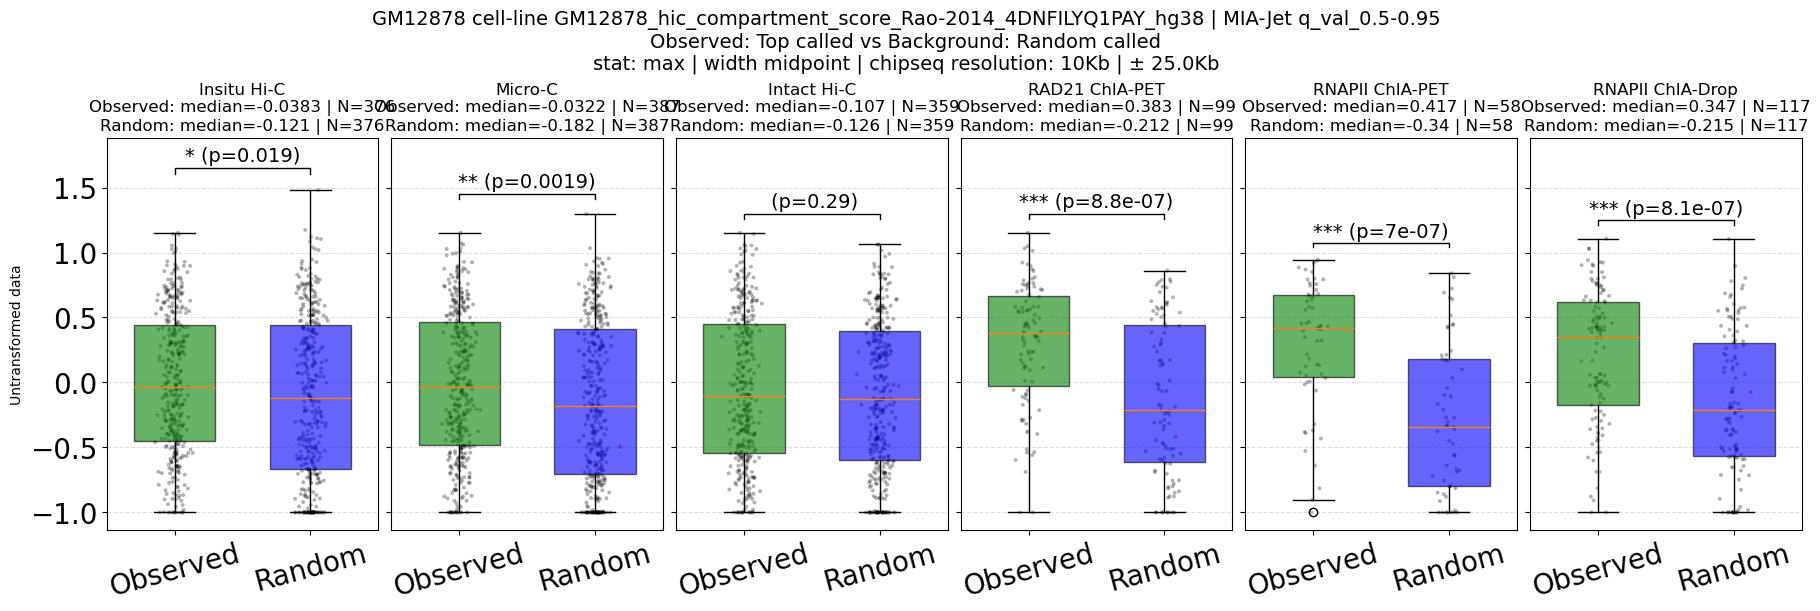

In [24]:
# PLOTTING
obs_type = collected_chipseq["observed_type"]
bg_type = collected_chipseq["background_type"]
stat = collected_chipseq["stat"]
chipseq_idx = collected_chipseq["chipseq_idx"]
chipseq_resolution = collected_chipseq["chipseq_resolution"]

obs_values = collected_chipseq["obs_values"]
bg_values = collected_chipseq["bg_values"]

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
obs_col, bg_col = "green", "blue"

num_exp = len(names)
fig, axes = plt.subplots(1, num_exp, figsize=(4 * num_exp * 0.75, 6),
                         sharey=True, layout="constrained")

axes = np.atleast_1d(axes)

for i, ax in enumerate(np.ravel(axes)):
    data_pair = []
    for raw_vals in (obs_values[i], bg_values[i]):
        vals = raw_vals[~np.isnan(raw_vals)]
        # vals = np.clip(vals, 0, None)
        # vals = np.log10(vals + 1)
        data_pair.append(vals)

    positions = [1, 2]
    add_pairwise_sig(ax, positions, data_pair, fontsize=14, y_pad=0.05)

    bp = ax.boxplot(data_pair, patch_artist=True,
                    positions=positions, widths=0.6)
    bp['boxes'][0].set_facecolor(obs_col); bp['boxes'][0].set_alpha(0.6)
    bp['boxes'][1].set_facecolor(bg_col);  bp['boxes'][1].set_alpha(0.6)

    for pos, vals in zip(positions, data_pair):
        x = np.full_like(vals, pos, dtype=float) + np.random.normal(0, 0.05, len(vals))
        ax.scatter(x, vals, s=8, alpha=0.3, color='k', edgecolor='none')

    ax.set_xticks(positions)
    ax.set_xticklabels(["Observed", "Random"], rotation=15, ha="center", fontsize=20)

    title_boxstat = title_boxplot(names_abrev[i], ["Observed", "Random"], data_pair)
    ax.set_title(title_boxstat)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("Untransformed data")

# after the plotting loop, before savefig/show
pad = 0.1  # fixed amount in data units
ymin, ymax = axes[0].get_ylim()
axes[0].set_ylim(ymin, ymax + pad)
y_tick_size = 20
for ax in np.ravel(axes):
    ax.tick_params(axis="y", labelsize=y_tick_size)

fig.suptitle(
    f"{data_name} {chip_names[chipseq_idx]} | MIA-Jet {rt}\n"
    f"Observed: {obs_type} vs Background: {bg_type}\n"
    f"stat: {stat} | width {bed_type} | chipseq resolution: {genomic_labels(chipseq_resolution)} | ± {genomic_labels(plusminus, N=1)}",
    fontsize=14
)

save_fname = (
    f"{save_path}/{data_name}_{bed_type}_{rt}_"
    f"{obs_type.replace(' ', '-')}_vs_{bg_type.replace(' ', '-')}_"
    f"{chip_names_abrev[chipseq_idx]}_chipseq_comparison_{plusminus}.png"
)
plt.savefig(save_fname, dpi=300)

plt.show()